In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

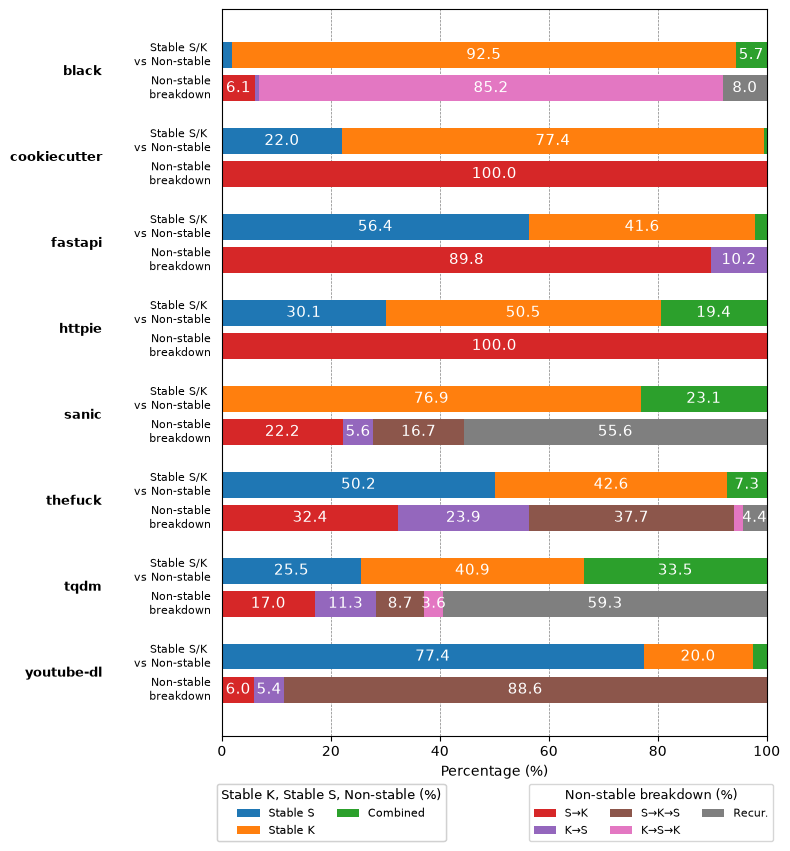

In [14]:
# Data from the LaTeX table
# Columns:
# Project, CI, Stable S, Stable K, S→K, K→S, S→K→S, K→S→K, Recur.
data = [
    ("black",        26347, 481,   24371, 91,  11, 0,   1273, 120),
    ("cookiecutter", 186,   41,    144,   1,   0,  0,   0,    0),
    ("fastapi",      2353,  1326,  978,   44,  5,  0,   0,    0),
    ("httpie",       612,   184,   309,   119, 0,  0,   0,    0),
    ("sanic",        78,    0,     60,    4,   1,  3,   0,    10),
    ("thefuck",      4377,  2196,  1863,  103, 76, 120, 5,    14),
    ("tqdm",         2764,  706,   1131,  158, 105,81,  33,   550),
    ("youtube-dl",   32378, 25060, 6481,  50,  45, 742, 0,    0),
]

cols = [
    "Project", "CI", "Stable S", "Stable K",
    "S→K", "K→S", "S→K→S", "K→S→K", "Recur."
]

df = pd.DataFrame(data, columns=cols)

transition_cols = ["S→K", "K→S", "S→K→S", "K→S→K", "Recur."]
df["Combined"] = df[transition_cols].sum(axis=1)


from matplotlib.transforms import blended_transform_factory

# ============================================================
# Combined plot:
# Side-by-side horizontal stacked bars per project
# Top:    Stable S / Stable K / Combined (% of CI)
# Bottom: transition breakdown (% of combined)
# ============================================================

plot1_cols = ["Stable S", "Stable K", "Combined"]
plot1 = df[["Project"] + plot1_cols].copy()
for col in plot1_cols:
    plot1[col] = plot1[col] / df["CI"] * 100

plot2 = df[["Project"] + transition_cols].copy()
for col in transition_cols:
    plot2[col] = plot2[col] / df["Combined"].replace(0, pd.NA) * 100

n = len(df)

group_step = 2 # 1.9 #1.5
height = 0.6 #0.34
inner_gap = 0.17 #0.42
colors = plt.get_cmap("tab10").colors

y_centers = np.arange(n) * group_step
offset = (height + inner_gap) / 2
y_ci = y_centers - offset
y_combined = y_centers + offset

fig, ax = plt.subplots(figsize=(8, 8))
fig.subplots_adjust(left=0.30, bottom=0.24, right=0.98, top=0.93)

# left = np.zeros(n)
# left_handles = []
# for i, col in enumerate(plot1_cols):
#     color = colors[i]
#     ax.barh(y_ci, plot1[col], height, left=left, color=color)
#     left_handles.append(Patch(facecolor=color, label=col))
#     left += plot1[col].to_numpy()

# left = np.zeros(n)
# right_handles = []
# for i, col in enumerate(transition_cols):
#     color = colors[i + len(plot1_cols)]
#     values = plot2[col].fillna(0)
#     ax.barh(y_combined, values, height, left=left, color=color)
#     right_handles.append(Patch(facecolor=color, label=col))
#     left += values.to_numpy()
     
##
label_threshold = 3.0  # do not label very tiny stacked segments

left = np.zeros(n)
left_handles = []
for i, col in enumerate(plot1_cols):
    color = colors[i]
    values = plot1[col].to_numpy()

    ax.barh(y_ci, values, height, left=left, color=color)
    left_handles.append(Patch(facecolor=color, label=col))

    for j, v in enumerate(values):
        if v >= label_threshold:
            ax.text(
                left[j] + v / 2,
                y_ci[j],
                f"{v:.1f}",
                ha="center",
                va="center",
                fontsize=11,
                color="white"
            )

    left += values


left = np.zeros(n)
right_handles = []
for i, col in enumerate(transition_cols):
    color = colors[i + len(plot1_cols)]
    values = plot2[col].fillna(0).to_numpy()

    ax.barh(y_combined, values, height, left=left, color=color)
    right_handles.append(Patch(facecolor=color, label=col))

    for j, v in enumerate(values):
        if v >= label_threshold:
            ax.text(
                left[j] + v / 2,
                y_combined[j],
                f"{v:.1f}",
                ha="center",
                va="center",
                fontsize=11,
                color="white"
            )

    left += values
##

label_trans = blended_transform_factory(ax.transAxes, ax.transData)
for i, proj in enumerate(df["Project"]):
    ax.text(-0.22, y_centers[i], proj, transform=label_trans,
            ha="right", va="center", fontweight="bold", fontsize = 9, clip_on=False)
    ax.text(-0.02, y_ci[i], "Stable S/K \n vs Non-stable", transform=label_trans,
            ha="right", va="center", fontsize=8, color="0.", clip_on=False)
    ax.text(-0.02, y_combined[i], "Non-stable\n breakdown", transform=label_trans,
            ha="right", va="center", fontsize=8, color="0.", clip_on=False)

ax.set_yticks([])
ax.set_xlabel("Percentage (%)", fontsize = 10)
#ax.set_title("RQ1: Per-Project Status Patterns", fontsize = 10)
ax.set_xlim(0, 100)
ax.invert_yaxis()

leg_left = fig.legend(
    handles=left_handles,
    loc="upper center",
    bbox_to_anchor=(0.42, 0.02),
    bbox_transform=fig.transFigure,
    ncol=2,
    frameon=True,
    fontsize=8,
    title="Stable K, Stable S, Non-stable (%)", 
    title_fontproperties={"size": 9}
)
fig.add_artist(leg_left)
fig.legend(
    handles=right_handles,
    loc="upper center",
    bbox_to_anchor=(0.82, 0.02),
    bbox_transform=fig.transFigure,
    ncol=3,
    frameon=True,
    fontsize=8,
    title="Non-stable breakdown (%)",
    title_fontproperties={"size": 9}
)

ax.grid(visible=True, axis='both', color='black', linestyle='--', linewidth=0.5, alpha=0.5)
ax.set_axisbelow(True) # Keeps the grid lines behind your bar charts

#out = Path("rq1_prevalence.png")
plt.tight_layout()
fig.savefig("rq1_prevalence.pdf", dpi=600, bbox_inches="tight")
#fig.savefig("rq1_prevalence.pdf", bbox_inches="tight")
plt.show()